# 03 - Analyse en Composantes Principales (ACP)

**Objectif** : réduire les 14 variables financières à un petit nombre de composantes non corrélées, et mesurer l'information conservée.

**Données** : `data/raw/genz_money_spends1.csv` (1 700 individus, 14 variables).

**Résultats produits** (lus par la page « 4. ACP Professionnel » de l'application) :
- `data/processed/acp_transformed_data.csv` : coordonnées des individus sur les composantes
- `data/results/acp_components_loadings.csv` : contribution de chaque variable à chaque composante
- `data/results/acp_eigenvalues.csv` : valeurs propres et variance expliquée
- `data/results/acp_complete_summary.json` : synthèse et critères de choix du nombre de composantes

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
DATA = Path("../data")
RAW, PROCESSED, RESULTS = DATA / "raw", DATA / "processed", DATA / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

from sklearn.decomposition import PCA

## 1. Chargement des données

In [2]:
# Jeu de données de 1 700 individus (séparateur ;)
df = pd.read_csv(RAW / "genz_money_spends1.csv", sep=";")
VARIABLES = [c for c in df.columns if c != "ID"]
X = df[VARIABLES]
print(df.shape, "| valeurs manquantes :", int(df.isna().sum().sum()))
X.describe().T.round(1)

(1700, 15) | valeurs manquantes : 0


,count,mean,std,min,25%,50%,75%,max
Age,1700.0,22.5,2.9,18.0,20.0,22.0,25.0,27.0
Income (USD),1700.0,4764.8,1877.1,1501.0,3149.8,4743.0,6419.8,7994.0
Rent (USD),1700.0,1155.6,495.2,300.0,724.0,1157.5,1589.8,1999.0
Groceries (USD),1700.0,357.1,142.6,100.0,237.0,362.0,482.2,599.0
Eating Out (USD),1700.0,272.1,131.8,50.0,157.0,266.5,387.2,499.0
Entertainment (USD),1700.0,209.1,109.6,20.0,113.0,210.0,303.2,399.0
Subscription Services (USD),1700.0,55.9,26.1,10.0,33.0,57.0,79.0,99.0
Education (USD),1700.0,1009.9,576.6,0.0,518.5,995.0,1513.5,1996.0
Online Shopping (USD),1700.0,362.9,197.1,20.0,191.0,370.0,539.0,699.0
Savings (USD),1700.0,1557.4,818.4,100.0,891.0,1563.5,2222.2,2999.0


## 2. Standardisation

Les variables ont des échelles très différentes (âge en années, revenus en milliers de dollars). Sans standardisation, l'ACP serait dominée par les variables de grande amplitude. Chaque variable est ramenée à une moyenne de 0 et un écart-type de 1.

In [3]:
X_scaled = StandardScaler().fit_transform(X)
print("Moyennes :", X_scaled.mean(axis=0).round(6)[:4], "...")
print("Écarts-types :", X_scaled.std(axis=0).round(6)[:4], "...")

Moyennes : [-0. -0. -0.  0.] ...
Écarts-types : [1. 1. 1. 1.] ...


## 3. ACP sur toutes les composantes

Le signe d'une composante est arbitraire. Pour des résultats stables d'une version de scikit-learn à l'autre, on fixe une convention : dans chaque composante, la variable qui contribue le plus a un coefficient positif.

In [4]:
pca = PCA().fit(X_scaled)
components = pca.components_.copy()
signs = np.sign(components[np.arange(len(components)), np.abs(components).argmax(axis=1)])
components *= signs[:, None]
scores = (X_scaled - pca.mean_) @ components.T

pc_names = [f"PC{i + 1}" for i in range(len(components))]
eigenvalues = pca.explained_variance_
variance_pct = pca.explained_variance_ratio_ * 100
cumulative_pct = np.cumsum(variance_pct)

eigen_df = pd.DataFrame({
    "Composante": pc_names,
    "Valeur propre": eigenvalues,
    "Variance expliquée (%)": variance_pct,
    "Variance cumulée (%)": cumulative_pct,
})
eigen_df.round(3)

,Composante,Valeur propre,Variance expliquée (%),Variance cumulée (%)
0,PC1,1.142,8.149,8.149
1,PC2,1.117,7.977,16.126
2,PC3,1.101,7.862,23.988
3,PC4,1.070,7.638,31.626
4,PC5,1.051,7.502,39.128
5,PC6,1.030,7.352,46.480
6,PC7,1.010,7.211,53.691
7,PC8,0.991,7.075,60.765
8,PC9,0.969,6.914,67.679
9,PC10,0.949,6.773,74.452


## 4. Choix du nombre de composantes

Trois critères classiques :
- **Kaiser** : garder les composantes de valeur propre > 1
- **80 %** et **90 %** de variance cumulée

In [5]:
k_kaiser = int((eigenvalues > 1).sum())
k_80 = int(np.argmax(cumulative_pct >= 80) + 1)
k_90 = int(np.argmax(cumulative_pct >= 90) + 1)
print(f"Kaiser : {k_kaiser} composantes | 80 % : {k_80} | 90 % : {k_90}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(pc_names, eigenvalues, color="steelblue")
ax[0].axhline(1, color="red", linestyle="--", label="Kaiser (valeur propre = 1)")
ax[0].set_title("Éboulis des valeurs propres")
ax[0].legend()
ax[1].plot(pc_names, cumulative_pct, marker="o")
for seuil in (80, 90):
    ax[1].axhline(seuil, linestyle="--", color="gray")
ax[1].set_title("Variance cumulée (%)")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(RESULTS / "acp_component_selection.png", dpi=150, bbox_inches="tight")
plt.show()

Kaiser : 7 composantes | 80 % : 11 | 90 % : 13


<Figure size 1400x500 with 2 Axes>

**Lecture** : les valeurs propres sont proches les unes des autres (de 1,14 à environ 0,7). Les variables sont donc peu corrélées entre elles : chaque composante n'explique qu'environ 7 à 8 % de la variance, et il faut 11 composantes pour atteindre 80 %. La réduction de dimension est limitée sur ce jeu de données.

## 5. Cercle des corrélations (PC1 - PC2)

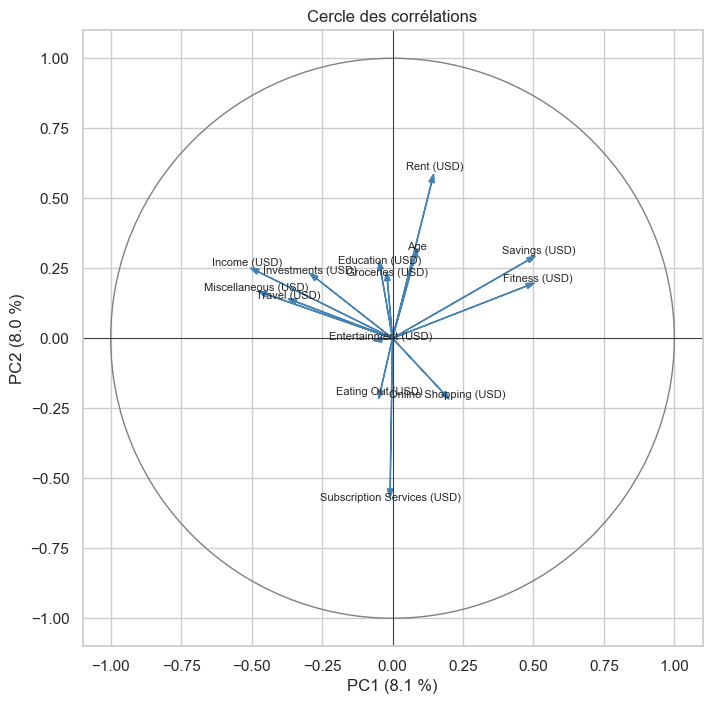

In [6]:
loadings = pd.DataFrame(components.T, index=VARIABLES, columns=pc_names)
correlations = loadings * np.sqrt(eigenvalues)

fig, ax = plt.subplots(figsize=(8, 8))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="gray"))
for var in VARIABLES:
    x, y = correlations.loc[var, "PC1"], correlations.loc[var, "PC2"]
    ax.arrow(0, 0, x, y, head_width=0.02, color="steelblue")
    ax.text(x * 1.08, y * 1.08, var, fontsize=8, ha="center")
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.axhline(0, color="black", linewidth=0.5)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel(f"PC1 ({variance_pct[0]:.1f} %)")
ax.set_ylabel(f"PC2 ({variance_pct[1]:.1f} %)")
ax.set_title("Cercle des corrélations")
plt.savefig(RESULTS / "acp_correlation_circles.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Projection des individus

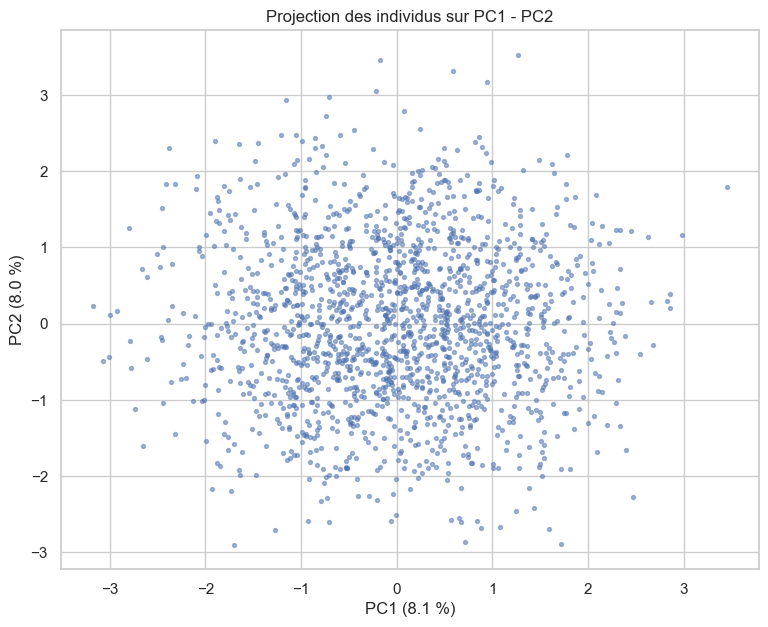

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(scores[:, 0], scores[:, 1], s=8, alpha=0.5)
ax.set_xlabel(f"PC1 ({variance_pct[0]:.1f} %)")
ax.set_ylabel(f"PC2 ({variance_pct[1]:.1f} %)")
ax.set_title("Projection des individus sur PC1 - PC2")
plt.savefig(RESULTS / "acp_individuals_map.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Sauvegarde des résultats

In [8]:
pd.DataFrame(scores, columns=pc_names).to_csv(PROCESSED / "acp_transformed_data.csv")
loadings.to_csv(RESULTS / "acp_components_loadings.csv")
eigen_df.to_csv(RESULTS / "acp_eigenvalues.csv", index=False)

summary = {
    "n_variables_originales": len(VARIABLES),
    "n_observations": len(df),
    "n_composantes_retenues": k_80,
    "variance_expliquee": float(cumulative_pct[k_80 - 1]),
    "variance_par_composante": {pc_names[i]: float(variance_pct[i]) for i in range(k_80)},
    "critere_80_pourcent": k_80,
    "critere_90_pourcent": k_90,
    "critere_kaiser": k_kaiser,
    "variables_originales": VARIABLES,
}
with open(RESULTS / "acp_complete_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(f"Résultats sauvegardés : {k_80} composantes retenues, {summary['variance_expliquee']:.1f} % de variance")

Résultats sauvegardés : 11 composantes retenues, 81.0 % de variance
